Section 1: Problem Statement & App Value Proposition:

This GUI is for engineers in reactor design who want to quickly size either single reactors, or multiple in series in seconds without having to use the traditional design equations. The design equations that are calculated by hand are, CSTR: V= Fa0X/-ra, PFR: V= Fa0 * integral of 0 to x (dx/-ra). Different reactor conditions can be tested very quickly.

Section 2: Project Description & Engineering Basis:

Reactor design equations: CSTR: V= Fa0X/-ra, PFR: V = Fa0 * integral of 0 to x (dx/-ra).
To use the GUI input the reactor conditions to generate a levenspiel plot to view the volume graphically or by eaxct value.

Section 3: GUI Sketch Image:

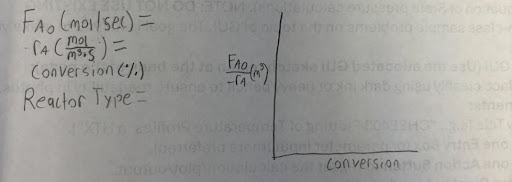

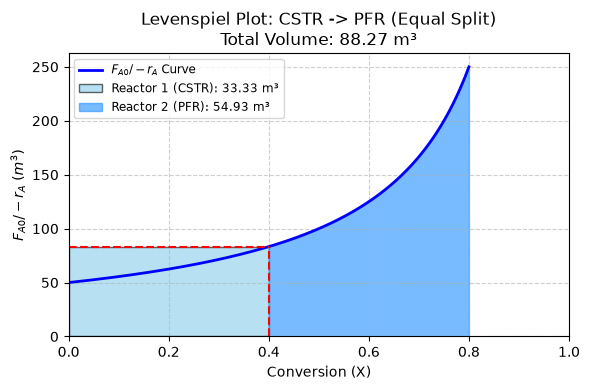

In [4]:
#Section 4: Python Code for the App and GUI: 

import tkinter as tk
from tkinter import ttk, messagebox
import matplotlib.pyplot as plt
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg
import numpy as np

class LevenspielApp:
    def __init__(self, root):
        self.root = root
        self.root.title("Levenspiel Plot Generator - Mixed Reactors in Series")
        self.create_widgets()

    def create_widgets(self):
        # FA0 Entry
        ttk.Label(self.root, text="Initial Molar Flow Rate, FA0 (mol/s):").grid(row=0, column=0, sticky="w", padx=10, pady=5)
        self.entry_fa0 = ttk.Entry(self.root)
        self.entry_fa0.insert(0, "10.0")
        self.entry_fa0.grid(row=0, column=1, padx=10, pady=5)

        # Initial Concentration Entry
        ttk.Label(self.root, text="Initial Concentration, CA0 (mol/m³):").grid(row=1, column=0, sticky="w", padx=10, pady=5)
        self.entry_ca0 = ttk.Entry(self.root)
        self.entry_ca0.insert(0, "2.0")
        self.entry_ca0.grid(row=1, column=1, padx=10, pady=5)

        # Rate Constant Entry
        ttk.Label(self.root, text="Rate Constant, k:").grid(row=2, column=0, sticky="w", padx=10, pady=5)
        self.entry_k = ttk.Entry(self.root)
        self.entry_k.insert(0, "0.1")
        self.entry_k.grid(row=2, column=1, padx=10, pady=5)

        # Reaction Order Dropdown
        ttk.Label(self.root, text="Reaction Order:").grid(row=3, column=0, sticky="w", padx=10, pady=5)
        self.order_type = ttk.Combobox(self.root, values=["1st Order (-rA = k*CA)", "2nd Order (-rA = k*CA^2)"], state="readonly")
        self.order_type.current(0)
        self.order_type.grid(row=3, column=1, padx=10, pady=5)

        # Target Conversion Entry
        ttk.Label(self.root, text="Target Conversion, X (%):").grid(row=4, column=0, sticky="w", padx=10, pady=5)
        self.entry_conversion = ttk.Entry(self.root)
        self.entry_conversion.insert(0, "80")
        self.entry_conversion.grid(row=4, column=1, padx=10, pady=5)

        # Reactor Configuration Dropdown
        ttk.Label(self.root, text="Reactor Configuration:").grid(row=5, column=0, sticky="w", padx=10, pady=5)
        self.config_type = ttk.Combobox(self.root, values=[
            "Single CSTR", 
            "Single PFR", 
            "CSTR -> PFR (Equal Split)", 
            "PFR -> CSTR (Equal Split)",
            "CSTR -> CSTR (2 in Series)",
            "PFR -> PFR (2 in Series)"
        ], state="readonly")
        self.config_type.current(2)  # Default to CSTR -> PFR
        self.config_type.grid(row=5, column=1, padx=10, pady=5)

        # Generate Button
        self.btn_plot = ttk.Button(self.root, text="Generate Plot", command=self.generate_plot_action)
        self.btn_plot.grid(row=6, column=0, columnspan=2, pady=10)

        # Matplotlib Canvas Setup
        self.fig, self.ax = plt.subplots(figsize=(6, 4), dpi=100)
        self.canvas = FigureCanvasTkAgg(self.fig, master=self.root)
        self.canvas.get_tk_widget().grid(row=7, column=0, columnspan=2, padx=10, pady=10)

    def get_rate(self, k, ca0, order, x_vals):
        if "1st Order" in order:
            return k * ca0 * (1 - x_vals)
        else:
            return k * (ca0**2) * ((1 - x_vals)**2)

    def generate_plot_action(self):
        try:
            fa0 = float(self.entry_fa0.get())
            ca0 = float(self.entry_ca0.get())
            k = float(self.entry_k.get())
            conv_percent = float(self.entry_conversion.get())
            config = self.config_type.get()
            order = self.order_type.get()

            if min(fa0, ca0, k) <= 0:
                raise ValueError("Flow rate, concentration, and k must be positive.")
            if not 0 < conv_percent < 100:
                raise ValueError("Conversion must be between 0 and 100%.")

            x_target = conv_percent / 100.0
            x_vals = np.linspace(0, min(x_target, 0.999), 300)
            ra_vals = self.get_rate(k, ca0, order, x_vals)
            levenspiel_y = fa0 / ra_vals

            stage_data = []
            total_volume = 0.0

            if config == "Single CSTR":
                ra_exit = self.get_rate(k, ca0, order, x_target)
                y_exit = fa0 / ra_exit
                v = y_exit * x_target
                stage_data.append(("CSTR", 0, x_target, y_exit, v))
                total_volume = v

            elif config == "Single PFR":
                v = np.trapezoid(levenspiel_y, x_vals)
                stage_data.append(("PFR", 0, x_target, levenspiel_y, x_vals, v))
                total_volume = v

            elif config in ["CSTR -> PFR (Equal Split)", "PFR -> CSTR (Equal Split)", "CSTR -> CSTR (2 in Series)", "PFR -> PFR (2 in Series)"]:
                x_mid = x_target / 2.0
                
                # Determine types for Stage 1 and Stage 2
                if "CSTR -> PFR" in config:
                    t1, t2 = "CSTR", "PFR"
                elif "PFR -> CSTR" in config:
                    t1, t2 = "PFR", "CSTR"
                elif "CSTR -> CSTR" in config:
                    t1, t2 = "CSTR", "CSTR"
                else:
                    t1, t2 = "PFR", "PFR"

                # --- Stage 1 (0 to x_mid) ---
                if t1 == "CSTR":
                    ra_exit1 = self.get_rate(k, ca0, order, x_mid)
                    y_exit1 = fa0 / ra_exit1
                    v1 = y_exit1 * x_mid
                    stage_data.append(("CSTR", 0, x_mid, y_exit1, v1))
                else:
                    x_sub1 = np.linspace(0, x_mid, 100)
                    y_sub1 = fa0 / self.get_rate(k, ca0, order, x_sub1)
                    v1 = np.trapezoid(y_sub1, x_sub1)
                    stage_data.append(("PFR", 0, x_mid, y_sub1, x_sub1, v1))

                # --- Stage 2 (x_mid to x_target) ---
                if t2 == "CSTR":
                    ra_exit2 = self.get_rate(k, ca0, order, x_target)
                    y_exit2 = fa0 / ra_exit2
                    v2 = y_exit2 * (x_target - x_mid)
                    stage_data.append(("CSTR", x_mid, x_target, y_exit2, v2))
                else:
                    x_sub2 = np.linspace(x_mid, x_target, 100)
                    y_sub2 = fa0 / self.get_rate(k, ca0, order, x_sub2)
                    v2 = np.trapezoid(y_sub2, x_sub2)
                    stage_data.append(("PFR", x_mid, x_target, y_sub2, x_sub2, v2))

                total_volume = v1 + v2

            self.update_plot(x_vals, levenspiel_y, stage_data, config, total_volume)

        except ValueError as e:
            messagebox.showerror("Input Error", str(e))

    def update_plot(self, x_vals, y_vals, stage_data, config, total_volume):
        self.ax.clear()

        # Plot full Levenspiel curve
        self.ax.plot(x_vals, y_vals, 'b-', linewidth=2, label=r'$F_{A0} / -r_A$ Curve')

        colors = ['skyblue', 'dodgerblue'] if "CSTR" in config else ['lightgreen', 'forestgreen']

        for i, data in enumerate(stage_data):
            rtype = data[0]
            if rtype == "CSTR":
                _, x_start, x_end, y_exit, v_stage = data
                width = x_end - x_start
                self.ax.add_patch(plt.Rectangle((x_start, 0), width, y_exit, 
                                                facecolor=colors[i % len(colors)], alpha=0.6, edgecolor='black',
                                                label=f'Reactor {i+1} (CSTR): {v_stage:.2f} m³'))
                self.ax.plot([x_start, x_end], [y_exit, y_exit], 'r--')
                self.ax.plot([x_end, x_end], [0, y_exit], 'r--')
            else:
                _, x_start, x_end, y_sub, x_sub, v_stage = data
                self.ax.fill_between(x_sub, 0, y_sub, color=colors[i % len(colors)], alpha=0.6, 
                                    label=f'Reactor {i+1} (PFR): {v_stage:.2f} m³')

        # Formatting
        self.ax.set_xlabel('Conversion (X)')
        self.ax.set_ylabel(r'$F_{A0} / -r_A$ ($m^3$)')
        self.ax.set_title(f'Levenspiel Plot: {config}\nTotal Volume: {total_volume:.2f} m³')
        self.ax.set_xlim(0, 1.0)
        self.ax.set_ylim(bottom=0)
        self.ax.grid(True, linestyle='--', alpha=0.6)
        self.ax.legend(loc='upper left', fontsize='small')

        self.fig.tight_layout()
        self.canvas.draw()

if __name__ == "__main__":
    root = tk.Tk()
    app = LevenspielApp(root)
    root.mainloop()

Section 5: AI Prompting Log:

1st Prompt: Based off this picture, create a graphical user interface python script that can take the molar flow rate, reaction rate, conversion percentage, and reactor type ( only CSTR and PFR) , to generate a Levenspiel plot.

2nd Prompt: Can the code be modified to where multiple reaction rates do not need to be specified but still generate a plot over the course of different conversions

3rd Prompt: Can you modify this code to be able to calculate reactor in series, for either a CSTR or a PFR?

4th prompt: Can you further modify the code to where either a CSTR can be followed in series by a PFR, or vice versa?

